# Customer Segmentation with K-Means and PCA

A focused unsupervised-learning project using NumPy to implement K-Means and PCA from scratch. We standardize three customer features, study the K-Means objective with the Elbow method, compare clustering with the Silhouette score, and visualize clusters in two dimensions.

**Dataset:** [Mall Customer Segmentation](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python), 200 customers. `CustomerID` is an identifier and is excluded from modeling.

## 1. Setup and data

If the CSV is not present, the next cell downloads the public Kaggle dataset. The data file is ignored by Git; the notebook and code are the portfolio artifact.

In [1]:
from pathlib import Path
import io
import zipfile
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

DATA_PATH = Path("data/Mall_Customers.csv")
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists():
    url = "https://www.kaggle.com/api/v1/datasets/download/vjchoudhary7/customer-segmentation-tutorial-in-python"
    with urllib.request.urlopen(url) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
        DATA_PATH.write_bytes(archive.read("Mall_Customers.csv"))

data = pd.read_csv(DATA_PATH)
data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 2. Explore and prepare features

K-Means uses Euclidean distance. Without scaling, variables with larger numeric ranges can dominate distance calculations. Standardization applies \(z = (x - \mu)/\sigma\), centering each feature at zero with unit variance. We fit the scaler once and reuse it for every later point.

In [2]:
data.shape, data.isna().sum(), data.describe(include="all")

((200, 5),
 CustomerID                0
 Gender                    0
 Age                       0
 Annual Income (k$)        0
 Spending Score (1-100)    0
 dtype: int64,
         CustomerID  Gender         Age  Annual Income (k$)  \
 count   200.000000     200  200.000000          200.000000   
 unique         NaN       2         NaN                 NaN   
 top            NaN  Female         NaN                 NaN   
 freq           NaN     112         NaN                 NaN   
 mean    100.500000     NaN   38.850000           60.560000   
 std      57.879185     NaN   13.969007           26.264721   
 min       1.000000     NaN   18.000000           15.000000   
 25%      50.750000     NaN   28.750000           41.500000   
 50%     100.500000     NaN   36.000000           61.500000   
 75%     150.250000     NaN   49.000000           78.000000   
 max     200.000000     NaN   70.000000          137.000000   
 
         Spending Score (1-100)  
 count               200.000000  
 un

In [3]:
FEATURES = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
scaler = StandardScaler()
X = scaler.fit_transform(data[FEATURES])
print(f"Rows: {len(X)} | Features: {FEATURES}")
print("Scaled feature means:", X.mean(axis=0).round(3))
print("Scaled feature stds: ", X.std(axis=0).round(3))

Rows: 200 | Features: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Scaled feature means: [-0. -0. -0.]
Scaled feature stds:  [1. 1. 1.]


## 3. K-Means from scratch

For points \(x_i\), assignment \(c_i\), and centroid \(\mu_k\), K-Means minimizes

\[J = \sum_{i=1}^{m} \|x_i - \mu_{c_i}\|^2.\]

Lloyd's algorithm alternates **assignment** to the nearest centroid and **update** to the mean of assigned points. Each step does not increase SSE, so it converges to a local optimum. It does not guarantee a global optimum. K-means++ seeds the starting centroids to make poor initialization less likely.

In [4]:
class KMeansScratch:
    """Lloyd K-Means with k-means++ seeding and NumPy distance operations."""

    def __init__(self, n_clusters=5, max_iter=300, tol=1e-4, random_state=42):
        if n_clusters < 1:
            raise ValueError("n_clusters must be positive")
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state

    def _initialize(self, X, rng):
        centers = [X[rng.integers(len(X))]]
        for _ in range(1, self.n_clusters):
            d2 = ((X[:, None, :] - np.asarray(centers)[None, :, :]) ** 2).sum(axis=2).min(axis=1)
            probabilities = d2 / d2.sum() if d2.sum() else None
            centers.append(X[rng.choice(len(X), p=probabilities)])
        return np.asarray(centers).copy()

    def _assign(self, X):
        distances = ((X[:, None, :] - self.centroids_[None, :, :]) ** 2).sum(axis=2)
        return distances.argmin(axis=1)

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or len(X) < self.n_clusters or not np.isfinite(X).all():
            raise ValueError("X must be a finite 2D array with at least K rows")
        rng = np.random.default_rng(self.random_state)
        self.centroids_ = self._initialize(X, rng)

        for iteration in range(self.max_iter):
            labels = self._assign(X)
            updated = self.centroids_.copy()
            for k in range(self.n_clusters):
                members = X[labels == k]
                if len(members):  # Keep the old center if a cluster is empty.
                    updated[k] = members.mean(axis=0)
            shift = np.linalg.norm(updated - self.centroids_)
            self.centroids_ = updated
            if shift <= self.tol:
                break

        self.labels_ = self._assign(X)
        residuals = X - self.centroids_[self.labels_]
        self.inertia_ = float((residuals ** 2).sum())
        self.n_iter_ = iteration + 1
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return ((X[:, None, :] - self.centroids_[None, :, :]) ** 2).sum(axis=2).argmin(axis=1)

## 4. Elbow method and cluster validation

SSE always decreases as K grows. Look for a bend where extra clusters deliver smaller improvements; this is a heuristic, not an automatic answer. Silhouette compares within-cluster distance \(a\) with distance to the nearest other cluster \(b\): \(s=(b-a)/\max(a,b)\). Values near 1 indicate better-separated groups, values near 0 overlap, and negative values can indicate questionable assignments.

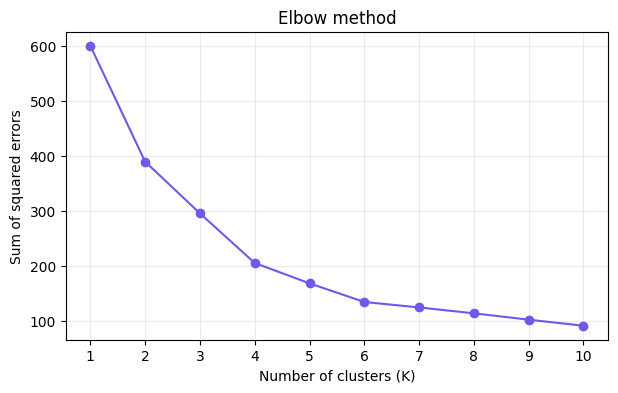

In [5]:
k_values = range(1, 11)
models = {k: KMeansScratch(k).fit(X) for k in k_values}
sse = [models[k].inertia_ for k in k_values]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(k_values), sse, marker="o", color="#7357e8")
ax.set(title="Elbow method", xlabel="Number of clusters (K)", ylabel="Sum of squared errors")
ax.set_xticks(list(k_values))
ax.grid(alpha=0.25)
plt.show()

Choose a K from the elbow and domain context. K=5 is a common demonstration choice for this dataset; it is not a universally correct customer segmentation. Compare silhouette scores as another signal.

In [6]:
silhouette_by_k = {k: silhouette_score(X, models[k].labels_) for k in range(2, 11)}
pd.Series(silhouette_by_k, name="silhouette").rename_axis("K").to_frame().round(3)

,silhouette
K,
2,0.335
3,0.359
4,0.404
5,0.417
6,0.431
7,0.414
8,0.389
9,0.392
10,0.376


## 5. PCA from scratch and cluster interpretation

PCA finds orthogonal directions of maximum variance. We eigendecompose the covariance matrix of the standardized features, sort eigenvectors by descending eigenvalue, then project onto the first two directions. Clustering still uses all three original standardized features; PCA only supplies a 2D visualization. The explained variance reports how much variation the plot retains.

In [7]:
def pca_2d(X):
    X = np.asarray(X, dtype=float)
    mean = X.mean(axis=0)
    centered = X - mean
    covariance = np.cov(centered, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    order = np.argsort(eigenvalues)[::-1]
    components = eigenvectors[:, order[:2]]
    explained = eigenvalues[order[:2]] / eigenvalues.sum()
    return centered @ components, explained, components

K = 5
model = models[K]
coordinates, explained_variance, pca_components = pca_2d(X)
print(f"K={K} | SSE={model.inertia_:.2f} | silhouette={silhouette_score(X, model.labels_):.3f}")
print(f"Variance retained in 2D: {explained_variance.sum():.1%}")

K=5 | SSE=168.25 | silhouette=0.417
Variance retained in 2D: 77.6%


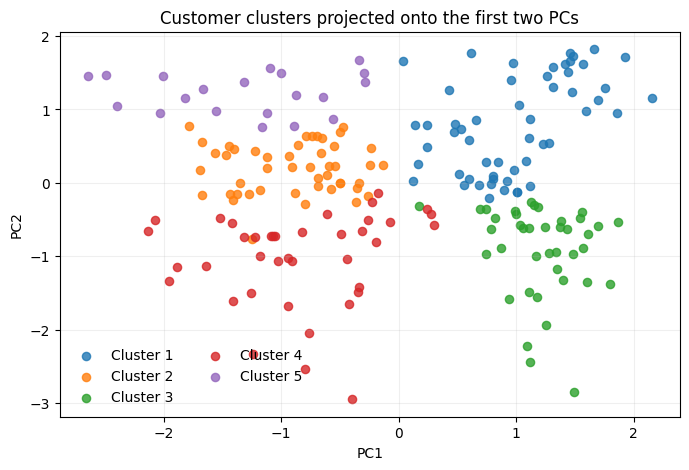

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for cluster in range(K):
    mask = model.labels_ == cluster
    ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=35, alpha=0.8, label=f"Cluster {cluster + 1}")
ax.set(title="Customer clusters projected onto the first two PCs", xlabel="PC1", ylabel="PC2")
ax.legend(frameon=False, ncol=2)
ax.grid(alpha=0.2)
plt.show()

In [9]:
profiles = data.assign(cluster=model.labels_).groupby("cluster").agg(
    customers=("CustomerID", "size"),
    mean_age=("Age", "mean"),
    mean_income=("Annual Income (k$)", "mean"),
    mean_spending=("Spending Score (1-100)", "mean"),
).round(1)
profiles

,customers,mean_age,mean_income,mean_spending
cluster,,,,
0,54,25.2,41.1,62.2
1,47,55.6,54.4,48.9
2,40,32.9,86.1,81.5
3,39,39.9,86.1,19.4
4,20,46.2,26.8,18.4


## 6. Predict a new customer

Transform a new point with the training scaler, then assign it to the closest learned centroid. Cluster numbers are arbitrary identifiers; use the profile table to interpret the segment.

In [10]:
new_customer = pd.DataFrame([[32, 65, 60]], columns=FEATURES)
new_scaled = scaler.transform(new_customer)
new_cluster = int(model.predict(new_scaled)[0])
new_pc = (new_scaled - X.mean(axis=0)) @ pca_components
print(f"Predicted segment: Cluster {new_cluster + 1}")
print(f"PCA coordinates: PC1={new_pc[0, 0]:.2f}, PC2={new_pc[0, 1]:.2f}")

Predicted segment: Cluster 1
PCA coordinates: PC1=0.62, PC2=-0.14


## Key takeaways

- Feature scaling matters because K-Means is distance-based.
- The K-Means objective is within-cluster SSE and the solution can depend on initialization.
- Use the elbow, silhouette, and business interpretation together when choosing K.
- PCA helps visualize high-dimensional data but does not create the clusters.
- These are exploratory groups from a small teaching dataset, not validated business segments.